# Final stage, Experiment 1: walk-forward evaluation by year

**Problem statement:** *Can we predict how severe a major power outage will become, using historical outage data and recent storm information available when the outage starts?*

**Question of this experiment:** how stable is the model over time, and is 2024 different from earlier years?

**Design (decided before running):**
- Data: extended outage data 2000–2024 + NOAA storms + NWS warnings (base model, no infrastructure data). The data pipeline (sections 0–6) is unchanged from the progress-stage notebook; all four storm rules are built. Outputs go to `results/` next to this notebook.
- Setup: **strict storm rule (R2)**, **scenario A (pre-event)**.
- **Expanding window:** for each 2-year test block (2008–09, 2010–11, …, 2022–23) the model is trained on **all years before the block** and tested on the block.
- **2024 is evaluated separately** (train 2000–2023, test 2024), because the OE-417 form changed in 2024. Section 9 compares 2024 with earlier years on the data itself.
- One fixed model per target (random forest, moderate settings, recency weights), so differences between blocks come from time, not from tuning. Model comparison and tuning are Experiment 2.
- Severe labels: Q1 / Q3 from each block's training years only.


-----

In [1]:
import io
import os
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (ExtraTreesClassifier, ExtraTreesRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, f1_score, mean_absolute_error, precision_score,
                             r2_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, mean_squared_error

## 1. Configuration


In [2]:
# project folder = the first parent folder that contains Data/
ROOT = os.getcwd()
while not os.path.isdir(os.path.join(ROOT, "Data")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
DATA_DIR = os.path.join(ROOT, "Data")
RAW_EXT = os.path.join(DATA_DIR, "ext_raw")  # ONI, Census, BEA downloads
PUDL = os.path.join(DATA_DIR, "pudl_raw")  # EIA-861 / FERC Form 1 parquet files
OUT_DIR = os.path.join(os.getcwd(), "results")  # CSV / PNG outputs, next to this notebook
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
TEST_START = pd.Timestamp("2022-01-01")  # used only for the summary printout in section 6
OUTAGE_FILE = "outage_extended.xlsx"  # Purdue 2000-2016 + DOE OE-417 2016-2024
NWS_FILE = os.path.join(DATA_DIR, "nws_raw", "nws_events.parquet")
NWS_START = pd.Timestamp(
    "2006-01-01"
)  # all watch / warning types archived from 12 Nov 2005
FORM_2024 = pd.Timestamp("2024-01-01")  # OE-417 form revision
REGIME_YEAR = 2011  # reporting changed around 2011

# targets
EXCLUDE_ZEROS = (
    True  # 0 customers / 0 minutes = no interruption -> not a severity target
)

# storm matching
LOOKBACK_HOURS = 24  # storm active within 24 h before the outage start
LOOKBACK = np.timedelta64(24, "h")
BUFFER = np.timedelta64(1, "h")  # strict rule: storm began >= 1 h before the start

# history features
SMOOTHING = 5.0  # shrink small-sample means toward the prior

# models
HALF_LIFE_YEARS = 4.0  # recency weight: 4 years older counts half
COST_RATIOS = [1, 3, 5]  # missed severe outage : false alarm

TASKS = {
    "customers_reg": ("reg", "log_customers"),
    "duration_reg": ("reg", "log_duration"),
    "is_severe": ("bin", None),
}

## 2. Data loading

### Outages

- `outage_extended.xlsx` has 4,279 reports: Purdue (2000 – Jul 2016) plus DOE OE-417 (Jul 2016 – 2024).

In [3]:
def merge_same_event(raw):
    """One row per (start, state): keep the report with the most information."""
    key = ["OUTAGE.START.DATE", "OUTAGE.START.TIME", "U.S._STATE"]
    info = raw["CUSTOMERS.AFFECTED"].notna().astype(int) + raw[
        "OUTAGE.DURATION"
    ].notna().astype(int)
    keep = (
        raw.assign(_info=info)
        .sort_values("_info", ascending=False, kind="mergesort")
        .drop_duplicates(key)
        .index
    )
    out = raw.loc[sorted(keep)].reset_index(drop=True)
    print(f"Merged reports of the same event: {len(raw)} -> {len(out)} rows")
    return out

###  NOAA Storm Events

- One CSV per year, 2000–2024.
- Event types are grouped into families (wind, winter, cold, tropical, tornado, flood, hail, heat, lightning, fire, other).
- Droughts are removed: they last months and are listed once per zone.
- Events are stored per state, sorted by begin time, so matching is fast.

In [4]:
NOAA_COLS = [
    "STATE",
    "BEGIN_DATE_TIME",
    "END_DATE_TIME",
    "EVENT_TYPE",
    "MAGNITUDE",
    "CZ_TYPE",
    "CZ_FIPS",
]


def read_csv_safely(path, **kwargs):
    """Read a NOAA CSV that may contain null bytes or mixed line endings."""
    with open(path, "rb") as fh:
        raw = fh.read().replace(b"\x00", b"")
    text = (
        raw.decode("latin1", errors="replace").replace("\r\n", "\n").replace("\r", "\n")
    )
    return pd.read_csv(io.StringIO(text), **kwargs)


def load_noaa(data_dir=DATA_DIR):
    files = sorted(
        os.path.join(data_dir, f)
        for f in os.listdir(data_dir)
        if re.search(r"StormEvents", f)
    )
    noaa_df = pd.concat(
        [
            read_csv_safely(
                f,
                on_bad_lines="skip",
                low_memory=False,
                dtype=str,
                usecols=lambda c: c in NOAA_COLS,
            )
            for f in files
        ],
        ignore_index=True,
    )
    print(f"NOAA data: {len(noaa_df)} rows from {len(files)} files")
    return noaa_df

In [5]:
EVENT_FAMILY = {
    "Thunderstorm Wind": "wind",
    "High Wind": "wind",
    "Strong Wind": "wind",
    "Marine Thunderstorm Wind": "wind",
    "Marine High Wind": "wind",
    "Marine Strong Wind": "wind",
    "Winter Storm": "winter",
    "Heavy Snow": "winter",
    "Ice Storm": "winter",
    "Blizzard": "winter",
    "Winter Weather": "winter",
    "Lake-Effect Snow": "winter",
    "Sleet": "winter",
    "Freezing Fog": "winter",
    "Frost/Freeze": "cold",
    "Extreme Cold/Wind Chill": "cold",
    "Cold/Wind Chill": "cold",
    "Hurricane (Typhoon)": "tropical",
    "Hurricane": "tropical",
    "Tropical Storm": "tropical",
    "Tropical Depression": "tropical",
    "Storm Surge/Tide": "tropical",
    "Marine Hurricane/Typhoon": "tropical",
    "Marine Tropical Storm": "tropical",
    "Tornado": "tornado",
    "Waterspout": "tornado",
    "Funnel Cloud": "tornado",
    "Flash Flood": "flood",
    "Flood": "flood",
    "Coastal Flood": "flood",
    "Lakeshore Flood": "flood",
    "Heavy Rain": "flood",
    "Hail": "hail",
    "Marine Hail": "hail",
    "Heat": "heat",
    "Excessive Heat": "heat",
    "Lightning": "lightning",
    "Marine Lightning": "lightning",
    "Wildfire": "fire",
}
FAMILIES = [
    "wind",
    "winter",
    "cold",
    "tropical",
    "tornado",
    "flood",
    "hail",
    "heat",
    "lightning",
    "fire",
    "other",
]
ONGOING_FAMILIES = ["wind", "winter", "tropical", "flood"]


def parse_noaa_time(s):
    out = pd.to_datetime(s, format="%d-%b-%y %H:%M:%S", errors="coerce")
    if out.isna().mean() > 0.5:  # other export format
        out = pd.to_datetime(s, errors="coerce")
    if getattr(out.dt, "tz", None) is not None:
        out = out.dt.tz_localize(None)
    return out


def prepare_noaa(noaa_df):
    """Clean NOAA once; return per-state arrays sorted by storm begin time."""
    n = noaa_df[[c for c in NOAA_COLS if c in noaa_df.columns]].copy()
    n["CLEAN_STATE"] = n["STATE"].astype(str).str.upper().str.strip()
    n["BEGIN_DATE_TIME"] = parse_noaa_time(n["BEGIN_DATE_TIME"])
    n["END_DATE_TIME"] = parse_noaa_time(n["END_DATE_TIME"])
    n = n.dropna(subset=["BEGIN_DATE_TIME", "END_DATE_TIME", "CLEAN_STATE"])
    n = n[n["EVENT_TYPE"] != "Drought"].copy()  # months long, per-zone duplicated
    n["MAGNITUDE"] = pd.to_numeric(n["MAGNITUDE"], errors="coerce")
    n["FAMILY"] = n["EVENT_TYPE"].map(EVENT_FAMILY).fillna("other")
    n["ZONE"] = (
        n["CZ_TYPE"].astype(str) + "_" + n["CZ_FIPS"].astype(str)
        if {"CZ_TYPE", "CZ_FIPS"}.issubset(n.columns)
        else "NA"
    )

    by_state = {}
    for state, g in n.sort_values("BEGIN_DATE_TIME").groupby("CLEAN_STATE"):
        by_state[state] = {
            "begin": g["BEGIN_DATE_TIME"].values.astype("datetime64[ns]"),
            "end": g["END_DATE_TIME"].values.astype("datetime64[ns]"),
            "mag": g["MAGNITUDE"].values.astype(float),
            "event": g["EVENT_TYPE"].astype(str).values,
            "family": g["FAMILY"].astype(str).values,
            "zone": g["ZONE"].astype(str).values,
        }
    return by_state

In [6]:
def load_raw():
    raw = pd.read_excel(os.path.join(DATA_DIR, OUTAGE_FILE))
    raw = merge_same_event(raw)
    if "N.STATES.AFFECTED" in raw.columns: 
        raw["N.STATES.AFFECTED"] = raw["N.STATES.AFFECTED"].fillna(1)
    noaa = prepare_noaa(load_noaa(DATA_DIR))
    for a in noaa.values():  # longest storm per state -> overlap search bound
        a["maxdur"] = (a["end"] - a["begin"]).max()
    return raw, noaa

### NWS watches, warnings and advisories (Iowa Environmental Mesonet)

The National Weather Service issues **watches** (A: conditions favour the hazard), **warnings** (W: hazard happening or imminent) and **advisories** (Y: less severe) for storms, floods, winter weather, heat and more. Source: the IEM archive of every VTEC event, downloaded per state and year by `download_nws_warnings.py`.

**Only real-time information is used:**
- `issue`: when the product was issued;
- `init_expire`: the expiry time announced **at issue**. The final expiry, which can be extended later, is not used.

Times are converted from UTC to the state's main time zone (DST-aware; states spanning two zones use the larger one, so up to 1 h off at the edges).

**Features at outage start** (same state):

| Feature | Meaning |
|---|---|
| `nws_warn_active`, `nws_watch_active`, `nws_adv_active` | warnings / watches / advisories in effect at outage start |
| `nws_warn_active_<family>` | warnings in effect, by family (wind, tornado, winter, tropical, flood, heat, cold, fire, other) |
| `nws_warn_24h`, `nws_warn_7d` | warnings issued in the last 24 h / 7 days |
| `nws_hours_since_warning` | hours since the last warning was issued (capped at 168) |

all product types are archived only from 12 Nov 2005, so outages **before 2006 get missing values** (filled by the model's imputer, with a "was missing" indicator).

In [7]:
NWS_FAMILY = {
    "SV": "wind",
    "HW": "wind",
    "WI": "wind",
    "EW": "wind",
    "LW": "wind",
    "GL": "wind",
    "SR": "wind",
    "TO": "tornado",
    "WS": "winter",
    "BZ": "winter",
    "IS": "winter",
    "WW": "winter",
    "LE": "winter",
    "ZR": "winter",
    "SN": "winter",
    "HS": "winter",
    "SQ": "winter",
    "LB": "winter",
    "SB": "winter",
    "HU": "tropical",
    "TR": "tropical",
    "TY": "tropical",
    "SS": "tropical",
    "HI": "tropical",
    "TI": "tropical",
    "FF": "flood",
    "FA": "flood",
    "FL": "flood",
    "CF": "flood",
    "LS": "flood",
    "HY": "flood",
    "EH": "heat",
    "HT": "heat",
    "XH": "heat",
    "EC": "cold",
    "WC": "cold",
    "FZ": "cold",
    "HZ": "cold",
    "FR": "cold",
    "CW": "cold",
    "XC": "cold",
    "FW": "fire",
}
NWS_FAMILIES = [
    "wind",
    "tornado",
    "winter",
    "tropical",
    "flood",
    "heat",
    "cold",
    "fire",
    "other",
]
NWS_NUM = (
    ["nws_warn_active", "nws_watch_active", "nws_adv_active"]
    + [f"nws_warn_active_{f}" for f in NWS_FAMILIES]
    + ["nws_warn_24h", "nws_warn_7d", "nws_hours_since_warning"]
)
STATE_TZ = {
    **{
        s: "America/New_York"
        for s in [
            "CT",
            "DE",
            "DC",
            "FL",
            "GA",
            "IN",
            "KY",
            "ME",
            "MD",
            "MA",
            "MI",
            "NH",
            "NJ",
            "NY",
            "NC",
            "OH",
            "PA",
            "RI",
            "SC",
            "VT",
            "VA",
            "WV",
        ]
    },
    **{
        s: "America/Chicago"
        for s in [
            "AL",
            "AR",
            "IL",
            "IA",
            "KS",
            "LA",
            "MN",
            "MS",
            "MO",
            "NE",
            "ND",
            "OK",
            "SD",
            "TN",
            "TX",
            "WI",
        ]
    },
    **{s: "America/Denver" for s in ["CO", "ID", "MT", "NM", "UT", "WY"]},
    "AZ": "America/Phoenix",
    **{s: "America/Los_Angeles" for s in ["CA", "NV", "OR", "WA"]},
    "AK": "America/Anchorage",
    "HI": "Pacific/Honolulu",
    "PR": "America/Puerto_Rico",
}


def load_nws(path=NWS_FILE):
    """Watches (A), warnings (W), advisories (Y) per state, local time, sorted by issue time."""
    ev = pd.read_parquet(path)
    ev = ev[
        ev["significance"].isin(["W", "A", "Y"]) & ev["state"].isin(STATE_TZ)
    ].copy()
    ev["family"] = ev["phenomena"].map(NWS_FAMILY).fillna("other")
    by_state = {}
    for st, g in ev.groupby("state"):
        tz = STATE_TZ[st]
        issue = (
            pd.to_datetime(g["issue"], utc=True, errors="coerce")
            .dt.tz_convert(tz)
            .dt.tz_localize(None)
        )
        expire = (
            pd.to_datetime(g["init_expire"], utc=True, errors="coerce")
            .dt.tz_convert(tz)
            .dt.tz_localize(None)
        )
        g = g.assign(issue_local=issue, expire_local=expire.fillna(issue)).dropna(
            subset=["issue_local"]
        )
        g = g.sort_values("issue_local")
        by_state[st] = {
            "issue": g["issue_local"].values.astype("datetime64[ns]"),
            "expire": g["expire_local"].values.astype("datetime64[ns]"),
            "sig": g["significance"].values,
            "family": g["family"].values,
        }
    print(
        f"NWS products: {len(ev)} (watches, warnings, advisories) in {len(by_state)} states"
    )
    return by_state


def nws_features(df, nws_by_state):
    """Real-time warning features at each outage start (NaN before NWS_START)."""
    h = np.timedelta64(1, "h")
    rows = []
    for st, t in zip(
        df["postal_code"].values, df["outage_start"].values.astype("datetime64[ns]")
    ):
        a = nws_by_state.get(st)
        if a is None or np.isnat(t) or t < np.datetime64(NWS_START):
            rows.append({c: np.nan for c in NWS_NUM})
            continue
        hi = np.searchsorted(a["issue"], t, side="right")  # issued before the start
        lo30 = np.searchsorted(a["issue"], t - np.timedelta64(30, "D"))
        idx = np.arange(lo30, hi)
        act = idx[a["expire"][idx] > t]  # in effect at the start
        sig, fam = a["sig"][act], a["family"][act]
        warn = idx[a["sig"][idx] == "W"]
        r = {
            "nws_warn_active": int((sig == "W").sum()),
            "nws_watch_active": int((sig == "A").sum()),
            "nws_adv_active": int((sig == "Y").sum()),
        }
        for f in NWS_FAMILIES:
            r[f"nws_warn_active_{f}"] = int(((sig == "W") & (fam == f)).sum())
        r["nws_warn_24h"] = int((a["issue"][warn] >= t - 24 * h).sum())
        r["nws_warn_7d"] = int((a["issue"][warn] >= t - 168 * h).sum())
        r["nws_hours_since_warning"] = (
            float(min((t - a["issue"][warn].max()) / h, 168.0)) if warn.size else 168.0
        )
        rows.append(r)
    return pd.DataFrame(rows, index=df.index)


nws_by_state = load_nws()

NWS products: 1352918 (watches, warnings, advisories) in 52 states


## 3. Storm matching (NOAA → outage)

Each outage is matched to storm events in the **same state**. Four rules are compared:


1. Original(Proposed): The original version only considered storms that **began** within the lookback window. Problem-A long storm that began before the window and was still active at outage start (for example, a flood that began 20 days earlier) was ignored.(the professor's feedback, W2 fix: overlap)
```
filter: 
lo = np.searchsorted(strom_begin >= lookback_window)# left | strom begins after lookback_window 
hi = np.searchsorted(strom_begin <= outage_start)# right | strom begains befor outage(strom after outage is ignored)
rule: (storm_begin <= outage_start) and  (storm_end >= lookback_window)
```

2. Overlap: To fix problem in original mode, a storm now counts if two things are both true:
1. calamity **began before the outage started**, and
2. calamity **had not already ended more than lookback_window (24) hours before the outage**. 

```
*maxdur is the longest storm duration in that state.
filter: 
lo= np.searchsorted(storm_begin >= (lookback_window − maxdur)) # left
hi = np.searchsorted(storm_begin <= outage_start) # right
rule: (storm_begin <= outage_start)
        and (storm_end >= lookback_window)
```

3. Strict: same as overlap, but the storm must have begun at least 1 hour before the outage:
```
filter: 
lo= np.searchsorted(storm_begin >= (lookback_window − maxdur)) #left
hi = np.searchsorted(storm_begin <= outage_start − buffer)#right | must begain 1 before the outage_start
rule:(storm_begin <= outage_start − buffer)
        and (storm_end >= lookback_window)
```
4. Completed: only storms that had fully ended before the outage started: This is the most  cautious mode; it ignores storms still in progress.
```
filter: 
lo = np.searchsorted(storm_begin >= lookback_window − maxdur)# left
hi = np.searchsorted(storm_begin <= outage_start - buffer) #right
rule: (storm_begin <= outage_start − buffer)
        and (lookback_window <= storm_end <= outage_start) #(storm_end >= lookback_window and storm_end <= outage_start)
```

**Features:** counts in the last 24 h and 7 days, number of zones and event types, counts per family, storm still active at start, hours since the last storm, maximum wind and hail of completed storms, and the most common event type. Damage, injury and death columns are never used.

In [8]:
def empty_storm_row(lookback_hours):
    """Feature values for an outage with no matching storm."""
    row = {
        "noaa_storm_count": 0,
        "noaa_count_7d": 0,
        "noaa_n_zones": 0,
        "noaa_n_types": 0,
        "noaa_n_ongoing": 0,
        "noaa_has_ongoing_storm": 0,
        "noaa_has_storm": 0,
        "hours_since_last_storm": float(lookback_hours),
        "noaa_max_wind_kt": np.nan,
        "noaa_max_hail_in": np.nan,
        "noaa_dominant_event_type": "None",
    }
    row.update({f"noaa_cnt_{f}": 0 for f in FAMILIES})
    row.update({f"noaa_ongoing_{f}": 0 for f in ONGOING_FAMILIES})
    return row


def storm_features_for_outage(a, start, lookback_hours):
    """
    PROPOSAL rule (R0): storms in the same state that BEGAN within the look-back window
    (outage start - LOOKBACK_HOURS <= BEGIN <= outage start). Long-running storms that began
    earlier are not counted (feedback W2).  Magnitudes use completed storms only
    (an ongoing storm's recorded peak may come after the outage began).
    """
    row = empty_storm_row(lookback_hours)
    lb = np.timedelta64(int(lookback_hours), "h")

    hi = np.searchsorted(a["begin"], start, side="right")
    row["noaa_count_7d"] = int(
        hi - np.searchsorted(a["begin"], start - np.timedelta64(7, "D"))
    )
    lo = np.searchsorted(
        a["begin"], start - lb
    )  # proposal rule: storm BEGAN within the window
    idx = np.arange(lo, hi)
    idx = idx[a["end"][idx] >= start - lb]
    if idx.size == 0:
        return row

    end, fam, ev = a["end"][idx], a["family"][idx], a["event"][idx]
    mag, zone = a["mag"][idx], a["zone"][idx]
    ongoing = end > start

    row["noaa_storm_count"] = int(idx.size)
    row["noaa_has_storm"] = 1
    row["noaa_n_zones"] = int(np.unique(zone).size)
    row["noaa_n_types"] = int(np.unique(ev).size)
    row["noaa_n_ongoing"] = int(ongoing.sum())
    row["noaa_has_ongoing_storm"] = int(ongoing.any())
    row["hours_since_last_storm"] = (
        0.0 if ongoing.any() else float((start - end.max()) / np.timedelta64(1, "h"))
    )
    for f in FAMILIES:
        row[f"noaa_cnt_{f}"] = int((fam == f).sum())
    for f in ONGOING_FAMILIES:
        row[f"noaa_ongoing_{f}"] = int(((fam == f) & ongoing).any())
    for col, f in [("noaa_max_wind_kt", "wind"), ("noaa_max_hail_in", "hail")]:
        m = mag[~ongoing & (fam == f)]
        m = m[~np.isnan(m)]
        row[col] = float(m.max()) if m.size else np.nan
    values, counts = np.unique(ev, return_counts=True)
    row["noaa_dominant_event_type"] = values[np.argmax(counts)]
    return row

In [9]:
def storm_row(a, t, mode):
    if mode == "original":
        return storm_features_for_outage(a, t, 24)
    row = empty_storm_row(24)
    t_known = t - BUFFER if mode in ("strict", "completed") else t
    hi = np.searchsorted(a["begin"], t_known, side="right")
    row["noaa_count_7d"] = int(
        hi - np.searchsorted(a["begin"], t_known - np.timedelta64(7, "D"))
    )
    lo = np.searchsorted(a["begin"], t - LOOKBACK - a["maxdur"])
    idx = np.arange(lo, hi)
    idx = idx[a["end"][idx] >= t - LOOKBACK]
    if mode == "completed":
        idx = idx[a["end"][idx] <= t]
    if idx.size == 0:
        return row
    end, fam, ev = a["end"][idx], a["family"][idx], a["event"][idx]
    mag, zone = a["mag"][idx], a["zone"][idx]
    ongoing = end > t
    row.update(
        noaa_storm_count=int(idx.size),
        noaa_has_storm=1,
        noaa_n_zones=int(np.unique(zone).size),
        noaa_n_types=int(np.unique(ev).size),
        noaa_n_ongoing=int(ongoing.sum()),
        noaa_has_ongoing_storm=int(ongoing.any()),
        hours_since_last_storm=(
            0.0 if ongoing.any() else float((t - end.max()) / np.timedelta64(1, "h"))
        ),
    )
    for f in FAMILIES:
        row[f"noaa_cnt_{f}"] = int((fam == f).sum())
    for f in ONGOING_FAMILIES:
        row[f"noaa_ongoing_{f}"] = int(((fam == f) & ongoing).any())
    for col, f in [("noaa_max_wind_kt", "wind"), ("noaa_max_hail_in", "hail")]:
        m = mag[~ongoing & (fam == f)]
        m = m[~np.isnan(m)]
        row[col] = float(m.max()) if m.size else np.nan
    values, counts = np.unique(ev, return_counts=True)
    row["noaa_dominant_event_type"] = values[np.argmax(counts)]
    return row


def storm_features(df, noaa, mode):
    rows = []
    for st, t in zip(
        df["clean_state"].values, df["outage_start"].values.astype("datetime64[ns]")
    ):
        a = noaa.get(st)
        rows.append(
            empty_storm_row(24) if a is None or np.isnat(t) else storm_row(a, t, mode)
        )
    return pd.DataFrame(rows, index=df.index)

## 4. Preprocessing

### Feature lists and leakage guard

`LEAKAGE_COLS` lists columns never used in  model inputs

In [10]:
STATIC_NUM = [
    "anomaly_level",
    "res_price",
    "com_price",
    "ind_price",
    "total_price",
    "res_sales",
    "com_sales",
    "ind_sales",
    "total_sales",
    "res_percen",
    "com_percen",
    "ind_percen",
    "res_customers",
    "com_customers",
    "ind_customers",
    "total_customers",
    "res_cust_pct",
    "com_cust_pct",
    "ind_cust_pct",
    "pc_realgsp_state",
    "pc_realgsp_usa",
    "pc_realgsp_rel",
    "pc_realgsp_change",
    "util_realgsp",
    "total_realgsp",
    "util_contri",
    "pi_util_ofusa",
    "population",
    "poppct_urban",
    "poppct_uc",
    "popden_urban",
    "popden_uc",
    "popden_rural",
    "areapct_urban",
    "areapct_uc",
    "pct_land",
    "pct_water_tot",
    "pct_water_inland",
]
SKEWED = [
    "res_sales",
    "com_sales",
    "ind_sales",
    "total_sales",
    "res_customers",
    "com_customers",
    "ind_customers",
    "total_customers",
    "util_realgsp",
    "total_realgsp",
    "population",
    "popden_urban",
    "popden_uc",
    "popden_rural",
]
TIME_NUM = [
    "start_month",
    "start_hour",
    "is_weekend",
    "post_regime",
    "month_sin",
    "month_cos",
    "hour_sin",
    "hour_cos",
]
NOAA_NUM = (
    [
        "noaa_storm_count",
        "noaa_count_7d",
        "noaa_n_zones",
        "noaa_n_types",
        "noaa_n_ongoing",
        "noaa_has_ongoing_storm",
        "noaa_has_storm",
        "hours_since_last_storm",
        "noaa_max_wind_kt",
        "noaa_max_hail_in",
    ]
    + [f"noaa_cnt_{f}" for f in FAMILIES]
    + [f"noaa_ongoing_{f}" for f in ONGOING_FAMILIES]
)
HIST_NUM = [
    "hist_state_n",
    "hist_state_n_365d",
    "hist_state_cust",
    "hist_state_dur",
    "hist_state_zero_rate",
    "hist_global_cust",
    "hist_global_dur",
]
RECENT_HIST = [
    "hist_global_cust_365d",
    "hist_global_dur_365d",
    "hist_state_cust_3y",
    "hist_state_dur_3y",
    "hist_state_n_30d",
    "hist_global_n_365d",
]
STORM_TE = [
    "hist_storm_cust",
    "hist_storm_dur",
    "hist_state_storm_cust",
    "hist_state_storm_dur",
]
CAUSE_TE = [
    "hist_cause_cust",
    "hist_cause_dur",
    "hist_state_cause_cust",
    "hist_state_cause_dur",
]
AREA_NUM = [
    "area_hist_n",
    "area_hist_n_365d",
    "area_hist_log_cust",
    "area_hist_log_dur",
    "area_hist_attack_share",
    "n_states_affected",
]
BASE_CAT = [
    "nerc_region",
    "climate_region",
    "climate_category",
    "clean_state",
    "noaa_dominant_event_type",
]
CAUSE_CAT = ["cause_reported"]
CAUSE_NUM = ["is_named_hurricane"]
GRID_NUM = []  # HIFLD state-level grid features: not used (no effect in v6)

# never allowed as model inputs (targets or post-event information)
LEAKAGE_COLS = [
    "cause_category",
    "cause_category_detail",
    "cust_reported_zero",
    "customers_affected",
    "demand_loss_mw",
    "hurricane_names",
    "log_customers",
    "log_duration",
    "obs",
    "outage_duration",
    "outage_restoration",
    "outage_restoration_date",
    "outage_restoration_time",
    "start_year",
    "year",
]
EXTRA_LEAKAGE = [
    "alert_criteria",
    "area_affected",
    "area_key",
    "event_type_raw",
    "same_start_reports",
    "source",
]
LEAKAGE_COLS, EXTRA_LEAKAGE = set(LEAKAGE_COLS), set(EXTRA_LEAKAGE)

ECON_EIA = [
    "res_price",
    "com_price",
    "ind_price",
    "total_price",
    "res_sales",
    "com_sales",
    "ind_sales",
    "total_sales",
    "res_percen",
    "com_percen",
    "ind_percen",
    "res_customers",
    "com_customers",
    "ind_customers",
    "total_customers",
    "res_cust_pct",
    "com_cust_pct",
    "ind_cust_pct",
]
ECON_BEA = [
    "pc_realgsp_state",
    "pc_realgsp_usa",
    "pc_realgsp_rel",
    "pc_realgsp_change",
    "util_realgsp",
    "total_realgsp",
    "util_contri",
    "pi_util_ofusa",
]

### Targets and time features

- Start and restoration timestamps are built from the date and time columns.
- Customers are normalised per 100,000 state population. Both targets are log-transformed.
- Rows are sorted by start time, because every split is chronological.
- Time features: month, hour, weekend, cyclic month/hour, and a reporting-regime flag (2011).

In [11]:
def combine_date_time(date_col, time_col):
    out = pd.to_datetime(
        date_col.astype(str) + " " + time_col.astype(str), errors="coerce"
    )
    alt = pd.to_datetime(date_col, errors="coerce").dt.normalize() + pd.to_timedelta(
        time_col.astype(str), errors="coerce"
    )
    return out.fillna(alt)


def create_targets(outage_df, exclude_zeros=EXCLUDE_ZEROS):
    """Timestamps + log targets; keep rows with a start time and >= 1 target."""
    df = outage_df.copy()
    df["OUTAGE_START"] = combine_date_time(
        df["OUTAGE.START.DATE"], df["OUTAGE.START.TIME"]
    )
    df["OUTAGE_RESTORATION"] = combine_date_time(
        df["OUTAGE.RESTORATION.DATE"], df["OUTAGE.RESTORATION.TIME"]
    )
    df["CLEAN_STATE"] = df["U.S._STATE"].astype(str).str.upper().str.strip()

    cust = pd.to_numeric(df["CUSTOMERS.AFFECTED"], errors="coerce").clip(lower=0)
    dur = pd.to_numeric(df["OUTAGE.DURATION"], errors="coerce").clip(lower=0)
    pop = pd.to_numeric(df["POPULATION"], errors="coerce")
    df["cust_reported_zero"] = (cust == 0).astype(float).where(cust.notna())
    if exclude_zeros:
        cust, dur = cust.mask(cust == 0), dur.mask(dur == 0)
    df["log_customers"] = np.log1p(cust / (pop / 100_000))  # per 100k population
    df["log_duration"] = np.log1p(dur)

    keep = (df["log_customers"].notna() | df["log_duration"].notna()) & df[
        "OUTAGE_START"
    ].notna()
    print(f"Rows kept: {keep.sum()} / {len(df)} (need a start time and >= 1 target)")
    # sort by time: every split / CV fold below is chronological
    return df[keep].sort_values("OUTAGE_START", kind="mergesort").reset_index(drop=True)


def add_time_features(df):
    st = df["OUTAGE_START"]
    df["start_month"] = st.dt.month
    df["start_hour"] = st.dt.hour
    df["start_year"] = st.dt.year  # reporting only, NOT a feature
    df["is_weekend"] = st.dt.dayofweek.isin([5, 6]).astype(int)
    df["post_regime"] = (st.dt.year >= REGIME_YEAR).astype(int)
    df["month_sin"] = np.sin(2 * np.pi * df["start_month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["start_month"] / 12)
    df["hour_sin"] = np.sin(2 * np.pi * df["start_hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["start_hour"] / 24)
    return df

### Outage-history features (known at outage start)

These use only **earlier outages already restored** before this one started; if the restoration time is unknown, the outage counts as known 7 days after its start. Small samples are shrunk toward a broader average.

| Group | Features |
|---|---|
| State history | number of past outages (all time and last 365 days), mean customers / duration, share of zero-customer reports |
| Recent history | 365-day global means, 3-year state means, outages in the last 30 days |
| Storm-status history | past outcomes of outages with the same storm / no-storm status (globally, then in the state) |
| Cause history (scenario B) | past outcomes for the same reported cause, globally and in the state |
| Area history (`area_hist_*`) | state + county history, precomputed in `outage_extended.xlsx` |

In [12]:
def add_history_features(df, k=SMOOTHING):
    """
    Summarise EARLIER outages in the same state whose outcome was already
    known (restored before this outage started; if restoration is missing,
    known 7 days after start). The current outage's own target is never used.
    """
    start = df["OUTAGE_START"].values.astype("datetime64[ns]")
    known_at = df["OUTAGE_RESTORATION"].values.astype("datetime64[ns]")
    bad = np.isnat(known_at) | (known_at < start)
    known_at = np.where(bad, start + np.timedelta64(7, "D"), known_at)
    state = df["CLEAN_STATE"].values
    lc = df["log_customers"].values.astype(float)
    ld = df["log_duration"].values.astype(float)
    zr = df["cust_reported_zero"].values.astype(float)

    def mean(v):
        v = v[~np.isnan(v)]
        return v.mean() if v.size else np.nan

    def smoothed(v, prior):
        v = v[~np.isnan(v)]
        if np.isnan(prior):
            return v.mean() if v.size else np.nan
        return (v.sum() + k * prior) / (v.size + k)

    out = {c: np.full(len(df), np.nan) for c in HIST_NUM}
    for i in range(len(df)):
        past = known_at < start[i]
        same = past & (state == state[i])
        g_c, g_d, g_z = mean(lc[past]), mean(ld[past]), mean(zr[past])
        out["hist_state_n"][i] = same.sum()
        out["hist_state_n_365d"][i] = (
            same & (start > start[i] - np.timedelta64(365, "D"))
        ).sum()
        out["hist_state_cust"][i] = smoothed(lc[same], g_c)
        out["hist_state_dur"][i] = smoothed(ld[same], g_d)
        out["hist_state_zero_rate"][i] = smoothed(zr[same], g_z)
        out["hist_global_cust"][i] = g_c
        out["hist_global_dur"][i] = g_d
    for c, v in out.items():
        df[c] = v
    return df

In [13]:
def add_history_v5(df, k=SMOOTHING):
    """
    Same rule as add_history_features: only EARLIER outages whose outcome was
    already known at this outage's start. Adds
      RECENT_HIST  rolling means (last 365 d globally, last 3 y in the state)
      STORM_TE     mean outcome of outages with the same storm / no-storm
                   status (globally, then same state) - a pre-event cause proxy
      CAUSE_TE     same, grouped by reported cause (scenario B only)
    """
    start = df["outage_start"].values.astype("datetime64[ns]")
    known_at = df["outage_restoration"].values.astype("datetime64[ns]")
    bad = np.isnat(known_at) | (known_at < start)
    known_at = np.where(bad, start + np.timedelta64(7, "D"), known_at)
    state = df["clean_state"].values
    storm = df["noaa_has_storm"].values
    cause = df["cause_reported"].fillna("na").values
    lc = df["log_customers"].values.astype(float)
    ld = df["log_duration"].values.astype(float)
    y1, y3 = np.timedelta64(365, "D"), np.timedelta64(3 * 365, "D")

    def mean(v):
        v = v[~np.isnan(v)]
        return v.mean() if v.size else np.nan

    def smoothed(v, prior):
        v = v[~np.isnan(v)]
        if np.isnan(prior):
            return v.mean() if v.size else np.nan
        return (v.sum() + k * prior) / (v.size + k)

    out = {c: np.full(len(df), np.nan) for c in RECENT_HIST + STORM_TE + CAUSE_TE}
    for i in range(len(df)):
        past = known_at < start[i]
        same = past & (state == state[i])
        recent = start > start[i] - y1
        reported = (start < start[i]) & (state == state[i])  # count only, no outcome
        g_c, g_d = mean(lc[past & recent]), mean(ld[past & recent])
        out["hist_global_cust_365d"][i], out["hist_global_dur_365d"][i] = g_c, g_d
        out["hist_state_cust_3y"][i] = smoothed(lc[same & (start > start[i] - y3)], g_c)
        out["hist_state_dur_3y"][i] = smoothed(ld[same & (start > start[i] - y3)], g_d)
        out["hist_state_n_30d"][i] = (
            reported & (start > start[i] - np.timedelta64(30, "D"))
        ).sum()
        out["hist_global_n_365d"][i] = ((start < start[i]) & recent).sum()
        for prefix, grp in [("storm", storm), ("cause", cause)]:
            g = past & (grp == grp[i])
            pc, pd_ = smoothed(lc[g], mean(lc[past])), smoothed(ld[g], mean(ld[past]))
            out[f"hist_{prefix}_cust"][i], out[f"hist_{prefix}_dur"][i] = pc, pd_
            out[f"hist_state_{prefix}_cust"][i] = smoothed(
                lc[g & (state == state[i])], pc
            )
            out[f"hist_state_{prefix}_dur"][i] = smoothed(
                ld[g & (state == state[i])], pd_
            )
    for c, v in out.items():
        df[c] = v
    return df

### Cause features and column cleaning

- Lower-case column names.
- Numeric conversion.
- Forward-fill of missing state statistics within each state.
- log1p transform of skewed amounts.

In [14]:
def add_cause_features(df):
    """Scenario B only: cause as reported, and whether a hurricane was named."""
    cause = df["CAUSE.CATEGORY"]
    df["cause_reported"] = (
        cause.astype(str).str.lower().str.strip().where(cause.notna())
    )
    df["is_named_hurricane"] = (
        df["HURRICANE.NAMES"].notna().astype(int)
        if "HURRICANE.NAMES" in df.columns
        else 0
    )
    return df


def clean_columns(df):
    """Lower-case names, numeric static columns, log of skewed columns."""
    df = df.rename(columns={c: c.replace(".", "_").lower() for c in df.columns})
    static = [c for c in STATIC_NUM if c in df.columns]
    df[static] = df[static].apply(pd.to_numeric, errors="coerce")
    # a missing state statistic <- same state's most recent earlier value
    df[static] = df.groupby("clean_state")[static].ffill()
    for c in SKEWED:
        if c in df.columns:
            df[c] = np.log1p(df[c].clip(lower=0))
    for c in BASE_CAT + CAUSE_CAT:
        if c in df.columns:
            df[c] = df[c].astype(object).where(df[c].notna(), np.nan)
    return df

### "As-of" economy, population and climate (W1 audit)

Purdue's economic columns are values **for the outage month or year**, which are published later. The strict variants replace them with information that existed before the outage started:

| Feature | Replacement |
|---|---|
| EIA sales, prices, customers | **previous year**, annual EIA-861 (via PUDL) |
| BEA real GDP and population | **previous year** |
| ONI climate anomaly | season **ending the month before** the outage |

In [15]:
def load_oni():
    """ONI anomaly per (year, month): the 3-month season centred on that month."""
    oni = pd.read_csv(os.path.join(RAW_EXT, "oni.txt"), sep=r"\s+")
    seasons = [
        "DJF",
        "JFM",
        "FMA",
        "MAM",
        "AMJ",
        "MJJ",
        "JJA",
        "JAS",
        "ASO",
        "SON",
        "OND",
        "NDJ",
    ]
    oni["MONTH"] = oni["SEAS"].map({s: i + 1 for i, s in enumerate(seasons)})
    return oni.rename(columns={"YR": "YEAR", "ANOM": "ANOMALY.LEVEL"})[
        ["YEAR", "MONTH", "ANOMALY.LEVEL"]
    ]


def load_population():
    a = pd.read_csv(os.path.join(RAW_EXT, "pop_2010s.csv"), encoding="latin1")
    b = pd.read_csv(os.path.join(RAW_EXT, "pop_2020_2024.csv"), encoding="latin1")
    rows = []
    for df, years in [(a, range(2010, 2020)), (b, range(2020, 2025))]:
        df = df[df["SUMLEV"].astype(int) == 40]
        for y in years:
            rows.append(
                pd.DataFrame(
                    {
                        "U.S._STATE": df["NAME"].values,
                        "YEAR": y,
                        "POPULATION": df[f"POPESTIMATE{y}"].values,
                    }
                )
            )
    return pd.concat(rows, ignore_index=True)


def load_bea(pop):
    """Annual real GSP (chained 2017 $, millions): total and utilities, per state + US."""
    f = os.path.join(RAW_EXT, "bea", "SAGDP9__ALL_AREAS_1997_2025.csv")
    b = pd.read_csv(f, encoding="latin1", dtype=str)
    b["GeoName"] = b["GeoName"].str.strip().str.strip('"')
    b["LineCode"] = pd.to_numeric(b["LineCode"], errors="coerce")
    years = [c for c in b.columns if c.isdigit()]
    long = b[b["LineCode"].isin([1, 10])].melt(
        id_vars=["GeoName", "LineCode"],
        value_vars=years,
        var_name="YEAR",
        value_name="v",
    )
    long["YEAR"] = long["YEAR"].astype(int)
    long["v"] = pd.to_numeric(long["v"], errors="coerce")
    w = long.pivot_table(
        index=["GeoName", "YEAR"], columns="LineCode", values="v"
    ).reset_index()
    w.columns = ["U.S._STATE", "YEAR", "TOTAL.REALGSP", "UTIL.REALGSP"]
    us = w[w["U.S._STATE"] == "United States"].set_index("YEAR")
    us_pop = pop.groupby("YEAR")["POPULATION"].sum()
    w = w.merge(pop, on=["U.S._STATE", "YEAR"], how="left")
    w["PC.REALGSP.STATE"] = 1e6 * w["TOTAL.REALGSP"] / w["POPULATION"]
    w["PC.REALGSP.USA"] = w["YEAR"].map(1e6 * us["TOTAL.REALGSP"] / us_pop)
    w["PC.REALGSP.REL"] = w["PC.REALGSP.STATE"] / w["PC.REALGSP.USA"]
    w = w.sort_values(["U.S._STATE", "YEAR"])
    w["PC.REALGSP.CHANGE"] = (
        100 * w.groupby("U.S._STATE")["PC.REALGSP.STATE"].pct_change()
    )
    w["UTIL.CONTRI"] = 100 * w["UTIL.REALGSP"] / w["TOTAL.REALGSP"]
    w["PI.UTIL.OFUSA"] = 100 * w["UTIL.REALGSP"] / w["YEAR"].map(us["UTIL.REALGSP"])
    return w.drop(columns="POPULATION")

In [16]:
def load_population_2000s():
    p = pd.read_csv(
        os.path.join(DATA_DIR, "ext_raw", "pop_2000s.csv"), encoding="latin1"
    )
    p = p[
        (p["STATE"] > 0)
        & (p["SEX"] == 0)
        & (p["ORIGIN"] == 0)
        & (p["RACE"] == 0)
        & (p["AGEGRP"] == 0)
    ]
    return pd.concat(
        [
            pd.DataFrame(
                {
                    "U.S._STATE": p["NAME"].values,
                    "YEAR": y,
                    "POPULATION": p[f"POPESTIMATE{y}"].values,
                }
            )
            for y in range(2000, 2010)
        ],
        ignore_index=True,
    )


def asof_economy(df):
    """
    W1 audit: replace values that are only published after the outage month / year
      * EIA sales, prices, customers  -> previous year, annual EIA-861 (PUDL)
      * GDP (BEA) and population      -> previous year
      * ONI climate anomaly           -> season ending the month before the outage
    """
    out = df.copy()
    year_prev = out["outage_start"].dt.year - 1

    s = pd.read_parquet(
        os.path.join(DATA_DIR, "pudl_raw", "core_eia861__yearly_sales.parquet")
    )
    s["YEAR"] = pd.to_datetime(s["report_date"]).dt.year
    cls = {"residential": "res", "commercial": "com", "industrial": "ind"}
    g = s.groupby(["state", "YEAR", "customer_class"])[
        ["sales_mwh", "sales_revenue", "customers"]
    ].sum()
    tot = g.groupby(level=[0, 1]).sum()
    e = pd.DataFrame(index=tot.index)
    for c, p in list(cls.items()) + [("total", "total")]:
        part = tot if c == "total" else g.xs(c, level="customer_class")
        e[f"{p}_sales"] = part["sales_mwh"]
        e[f"{p}_customers"] = part["customers"]
        e[f"{p}_price"] = (
            part["sales_revenue"] / part["sales_mwh"].where(part["sales_mwh"] > 0) / 10
        )
    for p in cls.values():
        e[f"{p}_percen"] = 100 * e[f"{p}_sales"] / e["total_sales"]
        e[f"{p}_cust_pct"] = 100 * e[f"{p}_customers"] / e["total_customers"]
    e = e.reset_index().rename(columns={"state": "postal_code"})
    k = pd.DataFrame(
        {"postal_code": out["postal_code"].values, "YEAR": year_prev.values}
    )
    m = k.merge(e, on=["postal_code", "YEAR"], how="left").set_axis(out.index)
    for c in ECON_EIA:
        out[c] = m[c]

    pop = pd.concat([load_population_2000s(), load_population()]).drop_duplicates(
        ["U.S._STATE", "YEAR"], keep="last"
    )
    bea = load_bea(pop).merge(pop, on=["U.S._STATE", "YEAR"], how="left")
    k = pd.DataFrame({"U.S._STATE": out["u_s__state"].values, "YEAR": year_prev.values})
    m = k.merge(bea, on=["U.S._STATE", "YEAR"], how="left").set_axis(out.index)
    for c in ECON_BEA:
        out[c] = m[c.upper().replace("_", ".").replace("PC.REALGSP.", "PC.REALGSP.")]
    out["population"] = m["POPULATION"]
    for c in [
        "res_sales",
        "com_sales",
        "ind_sales",
        "total_sales",
        "res_customers",
        "com_customers",
        "ind_customers",
        "total_customers",
        "util_realgsp",
        "total_realgsp",
        "population",
    ]:
        out[c] = np.log1p(out[c].clip(lower=0))

    oni = load_oni()  # centred 3-month seasons
    ym = (
        out["outage_start"].dt.year * 12 + out["outage_start"].dt.month - 1 - 2
    )  # centre m-2
    k = pd.DataFrame({"YEAR": (ym // 12).values, "MONTH": (ym % 12 + 1).values})
    out["anomaly_level"] = k.merge(oni, on=["YEAR", "MONTH"], how="left")[
        "ANOMALY.LEVEL"
    ].values
    out["climate_category"] = np.select(
        [out["anomaly_level"] >= 0.5, out["anomaly_level"] <= -0.5],
        ["warm", "cold"],
        "normal",
    )
    return out

### Grid features: EIA-861 and FERC Form 1 (previous year)

Used in the **proposed model** (Experiment 2). All values come from the **year before** the outage.

| Group | Features |
|---|---|
| G1 | state reliability: SAIDI / SAIFI / CAIDI, with and without major-event days |
| G2 | county reliability (via utility service territories), smart-meter share, distribution circuits |
| G3 | FERC Form 1 hardening: underground share, distribution plant per customer, overhead-line maintenance |

In [17]:
G1 = [
    "g1_saidi_w_med",
    "g1_saifi_w_med",
    "g1_caidi_w_med",
    "g1_saidi_wo_med",
    "g1_caidi_wo_med",
]
G2 = [
    "g2_c_saidi_w_med",
    "g2_c_saifi_w_med",
    "g2_c_caidi_w_med",
    "g2_ami_share",
    "g2_c_ami_share",
    "g2_circuits_per_1k_cust",
    "g2_volt_opt_share",
]
G3 = [
    "g3_underground_share",
    "g3_dist_plant_per_cust",
    "g3_oh_maint_per_cust",
    "g3_oh_maint_intensity",
]


def _read(name):
    return pd.read_parquet(os.path.join(PUDL, f"{name}.parquet"))


def _year(d):
    return pd.to_datetime(d["report_date"]).dt.year


def norm_county(s):
    s = str(s).lower()
    s = re.sub(r"\b(county|parish|borough|census area|city and borough)\b", "", s)
    s = s.replace("saint ", "st ").replace("st. ", "st ")
    return re.sub(r"[^a-z]", "", s)


def _wmean(d, keys, cols, w="w"):
    d = d.copy()
    out = {}
    for c in cols:
        ok = d[c].notna() & d[w].gt(0)
        num = (d.loc[ok, c] * d.loc[ok, w]).groupby([d.loc[ok, k] for k in keys]).sum()
        den = d.loc[ok, w].groupby([d.loc[ok, k] for k in keys]).sum()
        out[c] = num / den
    return pd.DataFrame(out).reset_index()


def utility_customers():
    s = _read("core_eia861__yearly_sales")
    s = s[s["customer_class"] != "total"] if "total" in set(s["customer_class"]) else s
    s["year"] = _year(s)
    return s.groupby(["utility_id_eia", "state", "year"], as_index=False)[
        "customers"
    ].sum()


def reliability():
    r = _read("core_eia861__yearly_reliability")
    r["year"] = _year(r)
    r["pref"] = (r["standard"] == "ieee_standard").astype(
        int
    )  # IEEE first, else other standard
    r = r.dropna(subset=["saidi_w_major_event_days_minutes"])
    r = r.sort_values("pref", ascending=False).drop_duplicates(
        ["utility_id_eia", "state", "year"]
    )
    return r.rename(
        columns={
            "saidi_w_major_event_days_minutes": "saidi_w",
            "saifi_w_major_event_days_customers": "saifi_w",
            "caidi_w_major_event_days_minutes": "caidi_w",
            "saidi_wo_major_event_days_minutes": "saidi_wo",
            "caidi_wo_major_event_days_minutes": "caidi_wo",
        }
    )[
        [
            "utility_id_eia",
            "state",
            "year",
            "customers",
            "saidi_w",
            "saifi_w",
            "caidi_w",
            "saidi_wo",
            "caidi_wo",
        ]
    ]


def ami():
    a = _read("core_eia861__yearly_advanced_metering_infrastructure")
    a["year"] = _year(a)
    cols = [
        "advanced_metering_infrastructure",
        "automated_meter_reading",
        "non_amr_ami",
    ]
    a = a.groupby(["utility_id_eia", "state", "year"], as_index=False)[cols].sum(
        min_count=1
    )
    tot = a[cols].sum(axis=1, min_count=1)
    a["ami_share"] = a["advanced_metering_infrastructure"] / tot.where(tot > 0)
    a["meters"] = tot
    return a[["utility_id_eia", "state", "year", "ami_share", "meters"]]


def ferc1_by_utility():
    """Per FERC respondent and year: hardening ratios and $ totals."""
    p = _read("core_ferc1__yearly_plant_in_service_sched204")
    lab = {
        "poles_towers_and_fixtures_distribution_plant": "poles",
        "overhead_conductors_and_devices_distribution_plant": "oh_cond",
        "underground_conduit_distribution_plant": "ug_conduit",
        "underground_conductors_and_devices_distribution_plant": "ug_cond",
        "distribution_plant": "dist_plant",
    }
    p = p[p["ferc_account_label"].isin(lab)]
    p = p.assign(k=p["ferc_account_label"].map(lab)).pivot_table(
        index=["utility_id_ferc1", "report_year"],
        columns="k",
        values="ending_balance",
        aggfunc="sum",
    )
    o = _read("core_ferc1__yearly_operating_expenses_sched320")
    o = (
        o[o["expense_type"] == "maintenance_of_overhead_lines"]
        .groupby(["utility_id_ferc1", "report_year"])["dollar_value"]
        .sum()
        .rename("oh_maint")
    )
    f = p.join(o, how="outer").reset_index()
    oh, ug = f[["poles", "oh_cond"]].sum(axis=1, min_count=1), f[
        ["ug_conduit", "ug_cond"]
    ].sum(axis=1, min_count=1)
    f["underground_share"] = ug / (oh + ug).where((oh + ug) > 0)
    f["oh_maint_intensity"] = f["oh_maint"] / oh.where(oh > 0)
    return f.rename(columns={"report_year": "year"})


def ferc1_state(cust):
    """Map FERC respondents to EIA utilities (via PUDL ids) and their states; customer-weighted."""
    f = ferc1_by_utility()
    fm = _read("core_pudl__assn_ferc1_pudl_utilities")[
        ["utility_id_ferc1", "utility_id_pudl"]
    ]
    em = _read("core_pudl__assn_eia_pudl_utilities")[
        ["utility_id_eia", "utility_id_pudl"]
    ]
    link = fm.merge(em, on="utility_id_pudl").drop_duplicates(
        ["utility_id_ferc1", "utility_id_eia"]
    )
    cu = cust.merge(link, on="utility_id_eia")
    ftot = (
        cu.groupby(["utility_id_ferc1", "year"])["customers"]
        .sum()
        .rename("ferc_customers")
    )
    f = f.merge(ftot.reset_index(), on=["utility_id_ferc1", "year"], how="inner")
    f = f[f["ferc_customers"] > 0]
    f["dist_plant_per_cust"] = np.log1p(f["dist_plant"] / f["ferc_customers"])
    f["oh_maint_per_cust"] = np.log1p(f["oh_maint"].clip(lower=0) / f["ferc_customers"])
    # each FERC utility counts in a state in proportion to its customers there
    w = cu.groupby(["utility_id_ferc1", "state", "year"], as_index=False)[
        "customers"
    ].sum()
    d = w.merge(f, on=["utility_id_ferc1", "year"]).rename(columns={"customers": "w"})
    cols = [
        "underground_share",
        "dist_plant_per_cust",
        "oh_maint_per_cust",
        "oh_maint_intensity",
    ]
    return _wmean(d, ["state", "year"], cols)

In [18]:
def build_grid_features(df):
    """df: v6 table (needs outage_start, postal_code, area_key). Returns grid features, same index."""
    cust = utility_customers()
    rel = reliability().merge(cust.rename(columns={"customers": "sales_customers"}),
                              on=["utility_id_eia", "state", "year"], how="left")
    rel["w"] = rel["customers"].fillna(rel["sales_customers"])
    rcols = ["saidi_w", "saifi_w", "caidi_w", "saidi_wo", "caidi_wo"]
    rel_state = _wmean(rel, ["state", "year"], rcols)

    am = ami().rename(columns={"meters": "w"})
    ami_state = _wmean(am, ["state", "year"], ["ami_share"])

    ds = _read("core_eia861__yearly_distribution_systems")
    ds["year"] = _year(ds)
    ds = ds.groupby(["state", "year"], as_index=False)[["distribution_circuits",
                                                        "circuits_with_voltage_optimization"]].sum()
    cst = cust.groupby(["state", "year"], as_index=False)["customers"].sum()
    ds = ds.merge(cst, on=["state", "year"], how="left")
    ds["circuits_per_1k_cust"] = 1000 * ds["distribution_circuits"] / ds["customers"].where(ds["customers"] > 0)
    ds["volt_opt_share"] = (ds["circuits_with_voltage_optimization"]
                            / ds["distribution_circuits"].where(ds["distribution_circuits"] > 0))

    st = _read("core_eia861__yearly_service_territory")
    st["year"] = _year(st)
    st["cty"] = st["county"].map(norm_county)
    st = st[["utility_id_eia", "state", "year", "cty"]].drop_duplicates()
    rel_cty = _wmean(st.merge(rel[["utility_id_eia", "state", "year", "w"] + rcols],
                              on=["utility_id_eia", "state", "year"]),
                     ["state", "cty", "year"], ["saidi_w", "saifi_w", "caidi_w"])
    ami_cty = _wmean(st.merge(am, on=["utility_id_eia", "state", "year"]),
                     ["state", "cty", "year"], ["ami_share"])
    fs = ferc1_state(cust)

    key = pd.DataFrame({"state": df["postal_code"].values,
                        "year": df["outage_start"].dt.year.values - 1,          # previous year
                        "cty": [norm_county(k.split("|", 1)[1]) if isinstance(k, str) and "|" in k
                                and not k.endswith("|statewide") else np.nan
                                for k in df["area_key"].values]}, index=df.index)
    out = pd.DataFrame(index=df.index)

    def lookup(table, keys, cols):
        return key[keys].merge(table, on=keys, how="left")[cols].set_axis(df.index)

    r = lookup(rel_state, ["state", "year"], rcols)
    out["g1_saidi_w_med"], out["g1_saidi_wo_med"] = np.log1p(r["saidi_w"]), np.log1p(r["saidi_wo"])
    out["g1_saifi_w_med"], out["g1_caidi_w_med"], out["g1_caidi_wo_med"] = r["saifi_w"], np.log1p(r["caidi_w"]), np.log1p(r["caidi_wo"])

    rc = lookup(rel_cty, ["state", "cty", "year"], ["saidi_w", "saifi_w", "caidi_w"])
    out["g2_c_saidi_w_med"] = np.log1p(rc["saidi_w"]).fillna(out["g1_saidi_w_med"])
    out["g2_c_saifi_w_med"] = rc["saifi_w"].fillna(out["g1_saifi_w_med"])
    out["g2_c_caidi_w_med"] = np.log1p(rc["caidi_w"]).fillna(out["g1_caidi_w_med"])
    out["g2_ami_share"] = lookup(ami_state, ["state", "year"], ["ami_share"])["ami_share"]
    out["g2_c_ami_share"] = lookup(ami_cty, ["state", "cty", "year"], ["ami_share"])["ami_share"].fillna(out["g2_ami_share"])
    dd = lookup(ds, ["state", "year"], ["circuits_per_1k_cust", "volt_opt_share"])
    out["g2_circuits_per_1k_cust"], out["g2_volt_opt_share"] = dd["circuits_per_1k_cust"], dd["volt_opt_share"]

    f = lookup(fs, ["state", "year"], ["underground_share", "dist_plant_per_cust",
                                       "oh_maint_per_cust", "oh_maint_intensity"])
    out["g3_underground_share"], out["g3_dist_plant_per_cust"] = f["underground_share"], f["dist_plant_per_cust"]
    out["g3_oh_maint_per_cust"], out["g3_oh_maint_intensity"] = f["oh_maint_per_cust"], f["oh_maint_intensity"]
    out["_county_matched"] = rc["saidi_w"].notna()
    return out

### Assemble one feature table per storm-matching variant

In [19]:
def base_table(raw):
    """Targets, time, outage history, cause; NOAA columns are added per mode later."""
    df = create_targets(raw)
    df = add_time_features(df)
    df = add_history_features(df)
    df = add_cause_features(df)
    df = clean_columns(df)
    df["regime_2024"] = (df["outage_start"] >= FORM_2024).astype(int)
    return df


def build_run_tables(raw, noaa):
    """One feature table per storm-matching / as-of variant."""
    tab0 = base_table(raw)
    tab_asof = asof_economy(tab0)
    grid = build_grid_features(tab0).drop(columns="_county_matched")
    nws = nws_features(
        tab0, nws_by_state
    )  # real-time NWS warnings (same for every rule)
    tables = {}
    for name, mode, asof in [
        ("original", "original", False),
        ("overlap", "overlap", False),
        ("strict", "strict", True),
        ("completed", "completed", True),
    ]:
        t0 = time.time()
        d = (tab_asof if asof else tab0).copy()
        d = d.join(storm_features(d, noaa, mode))
        d = add_history_v5(d)  # storm-status history needs NOAA
        d = d.join(grid).join(nws)
        tables[name] = d
        print(
            f"  features '{name}': {d['noaa_has_storm'].mean():.1%} outages with a storm "
            f"({time.time() - t0:.0f}s)",
            flush=True,
        )
    return tables

In [20]:
def base_feature_sets(df, area=True, grid=False):
    num = [
        c
        for c in STATIC_NUM
        + TIME_NUM
        + ["regime_2024"]
        + NOAA_NUM
        + HIST_NUM
        + RECENT_HIST
        + STORM_TE
        + (AREA_NUM if area else [])
        + (GRID_NUM if grid else [])
        if c in df.columns
    ]
    cat = [c for c in BASE_CAT if c in df.columns]
    sets = {
        "A_pre_event": (num, cat),
        "B_with_cause": (num + CAUSE_NUM + CAUSE_TE, cat + CAUSE_CAT),
    }
    used = {c for n, c_ in sets.values() for c in n + c_}
    bad = (LEAKAGE_COLS | EXTRA_LEAKAGE) & used
    assert not bad, f"leakage: {bad}"
    return sets


def feature_sets(df, scen, noaa=True, grid=False, nws=True):
    """noaa: NOAA storm features; nws: NWS warning features; grid: EIA-861 / FERC Form 1 (proposed model)."""
    num, cat = base_feature_sets(df, area=True, grid=False)[scen]
    if not noaa:
        drop = set(NOAA_NUM + STORM_TE + ["noaa_dominant_event_type"])
        num, cat = [c for c in num if c not in drop], [c for c in cat if c not in drop]
    if nws:
        num = num + [c for c in NWS_NUM if c in df.columns]
    if grid:
        num = num + G1 + G2 + G3
    return num, cat

## 5. Models and preprocessing

- **Model input preprocessing** (`build_preprocessor`), fitted on training rows only:
  - numeric: median imputation + missing-value indicator, then standard scaling
  - categorical: one-hot encoding, categories seen fewer than 10 times grouped together
- The models themselves (library defaults, then a grid search) are defined in section 7.

In [21]:
def build_preprocessor(num, cat):
    """Imputers / scaler / encoder are fitted on the training fold only."""
    return ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                        ("sc", StandardScaler()),
                    ]
                ),
                num,
            ),
            (
                "cat",
                Pipeline(
                    [
                        (
                            "imp",
                            SimpleImputer(strategy="constant", fill_value="missing"),
                        ),
                        (
                            "oh",
                            OneHotEncoder(
                                handle_unknown="infrequent_if_exist",
                                min_frequency=10,
                                sparse_output=False,
                            ),
                        ),
                    ]
                ),
                cat,
            ),
        ]
    )

### Labels

Q1 and Q3 come from the **training** rows only. `is_severe` = Level III in customers or duration.

In [22]:
def quartile_level(x, q1, q3):
    """0 = Level I, 1 = Level II, 2 = Level III."""
    return np.select([x < q1, x > q3], [0, 2], default=1)


def task_rows(d, kind, target):
    if kind == "bin":
        return d[d["log_customers"].notna() & d["log_duration"].notna()]
    return d[d[target].notna()]


def make_labels(kind, target, ref, *frames):
    """Labels for each frame; Q1/Q3 are taken from `ref` (training period)."""
    if kind == "reg":
        return [f[target].values.astype(float) for f in frames]
    qc = ref["log_customers"].quantile([0.25, 0.75]).values
    qd = ref["log_duration"].quantile([0.25, 0.75]).values
    labels = []
    for f in frames:
        if kind == "multi":
            labels.append(
                quartile_level(
                    f[target].values, *(qc if target == "log_customers" else qd)
                )
            )
        else:
            severe = (quartile_level(f["log_customers"].values, *qc) == 2) | (
                quartile_level(f["log_duration"].values, *qd) == 2
            )
            labels.append(severe.astype(int))
    return labels

### Prediction helper and recency weights

- `predict`: regression values, or the probability of the positive class.
- `recency_weights`: an outage 4 years older counts half.

In [23]:
def predict(pipe, kind, X):
    if kind == "reg":
        return pipe.predict(X)
    full = np.zeros((len(X), 2 if kind == "bin" else 3))
    full[:, pipe.classes_.astype(int)] = pipe.predict_proba(X)
    return full[:, 1] if kind == "bin" else full


def recency_weights(d, half_life=HALF_LIFE_YEARS):
    age = (d["outage_start"].max() - d["outage_start"]).dt.days.values / 365.25
    return 0.5 ** (age / half_life)

## 6. Load data and build the feature tables


In [24]:
t0 = time.time()
raw, noaa = load_raw()
print("Building feature tables ...")
tables = build_run_tables(raw, noaa)

# W2 evidence: active storms the old 14-day rule missed
o, f = tables["original"], tables["overlap"]
added = (f["noaa_storm_count"] - o["noaa_storm_count"]).clip(lower=0)
print(
    f"Overlap matching adds storms to {(added > 0).sum()} outages ({(added > 0).mean():.1%}), "
    f"{int(added.sum())} storm records"
)

df = tables["strict"]
dev, test = df[df["outage_start"] < TEST_START], df[df["outage_start"] >= TEST_START]
print(
    f"train (before {TEST_START.date()}): {len(dev)} outages | test (from {TEST_START.date()}): {len(test)} outages | "
    f"{(time.time() - t0) / 60:.1f} min"
)
display(
    pd.DataFrame(
        {
            "customers known": [
                dev["log_customers"].notna().sum(),
                test["log_customers"].notna().sum(),
            ],
            "duration known": [
                dev["log_duration"].notna().sum(),
                test["log_duration"].notna().sum(),
            ],
        },
        index=["train", "test"],
    )
)

Merged reports of the same event: 4279 -> 4195 rows


NOAA data: 1552468 rows from 25 files


Building feature tables ...
Rows kept: 3817 / 4195 (need a start time and >= 1 target)


  features 'original': 62.7% outages with a storm (4s)


  features 'overlap': 71.2% outages with a storm (4s)


  features 'strict': 70.4% outages with a storm (4s)


  features 'completed': 57.7% outages with a storm (4s)


Overlap matching adds storms to 1378 outages (36.1%), 20345 storm records
train (before 2022-01-01): 2722 outages | test (from 2022-01-01): 1095 outages | 0.9 min


,customers known,duration known
train,1466,2613
test,320,964


## 7. Experiment 1: walk-forward evaluation

Expanding window, 2-year test blocks, strict rule, scenario A. Metrics on each test block:
- customers and duration: R², MAE (log scale) and Spearman rank correlation;
- is_severe: ROC-AUC, PR-AUC and the share of severe outages in the block (PR-AUC must be read against it).

In [25]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import average_precision_score, mean_absolute_error, r2_score, roc_auc_score

WF_RULE, WF_SCEN = "strict", "A_pre_event"
WF_BLOCKS = [(y, y + 1) for y in range(2008, 2024, 2)]  # 2008-09, 2010-11, ..., 2022-23
WF_2024 = (2024, 2024)  # evaluated separately
WF_PRED = {}  # (test block, task) -> (true values, predictions), used for the bootstrap in section 10


def wf_model(kind):
    """One fixed model per target (no tuning here)."""
    if kind == "reg":
        return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.33,
                                     random_state=SEED, n_jobs=-1)
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features=0.33,
                                  class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)


def wf_block(df, y0, y1, num, cat):
    """Train on all years before y0, test on y0..y1."""
    yr = df["outage_start"].dt.year
    train, test = df[yr < y0], df[(yr >= y0) & (yr <= y1)]
    row = {"test_years": f"{y0}-{y1}" if y1 > y0 else str(y0), "train_years": f"2000-{y0 - 1}",
           "n_train": len(train), "n_test": len(test)}
    for task, (kind, target) in TASKS.items():
        d_tr, d_te = task_rows(train, kind, target), task_rows(test, kind, target)
        y_tr, y_te = make_labels(kind, target, train, d_tr, d_te)
        if len(d_te) < 10 or (kind == "bin" and len(np.unique(y_te)) < 2):
            continue
        pipe = Pipeline([("pre", build_preprocessor(num, cat)), ("model", wf_model(kind))])
        pipe.fit(d_tr[num + cat], y_tr, model__sample_weight=recency_weights(d_tr))
        p = predict(pipe, kind, d_te[num + cat])
        WF_PRED[(row["test_years"], task)] = (np.asarray(y_te), np.asarray(p))
        if kind == "reg":
            k = task.replace("_reg", "")
            row.update({f"{k}_n": len(y_te), f"{k}_R2": r2_score(y_te, p), f"{k}_MAE": mean_absolute_error(y_te, p),
                        f"{k}_rho": spearmanr(y_te, p).correlation})
        else:
            row.update({"severe_n": len(y_te), "severe_share": y_te.mean(),
                        "severe_ROC_AUC": roc_auc_score(y_te, p), "severe_PR_AUC": average_precision_score(y_te, p)})
    return row


t0 = time.time()
df = tables[WF_RULE]
num, cat = feature_sets(df, WF_SCEN)
wf = pd.DataFrame([wf_block(df, y0, y1, num, cat) for y0, y1 in WF_BLOCKS + [WF_2024]])
wf.to_csv(os.path.join(OUT_DIR, "exp1_walk_forward.csv"), index=False)
print(f"walk-forward done in {time.time() - t0:.0f}s")
display(wf.round(3))

walk-forward done in 77s


,test_years,train_years,n_train,n_test,customers_n,customers_R2,customers_MAE,customers_rho,duration_n,duration_R2,duration_MAE,duration_rho,severe_n,severe_share,severe_ROC_AUC,severe_PR_AUC
0,2008-2009,2000-2007,328,181,139,0.199,0.952,0.470,181,0.191,1.204,0.472,139,0.360,0.677,0.627
1,2010-2011,2000-2009,509,322,195,0.485,0.784,0.558,318,0.136,1.342,0.481,191,0.330,0.652,0.439
2,2012-2013,2000-2011,831,298,139,0.339,1.115,0.621,296,0.249,1.834,0.580,137,0.358,0.741,0.666
3,2014-2015,2000-2013,1129,216,89,0.437,1.138,0.564,206,0.078,1.931,0.405,79,0.278,0.687,0.416
4,2016-2017,2000-2015,1345,238,127,0.102,1.239,0.531,218,0.102,1.735,0.519,107,0.439,0.640,0.564
5,2018-2019,2000-2017,1583,454,205,0.266,1.149,0.614,425,0.166,1.638,0.410,176,0.347,0.702,0.566
6,2020-2021,2000-2019,2037,685,296,0.272,1.310,0.639,647,0.179,1.580,0.437,258,0.360,0.690,0.560
7,2022-2023,2000-2021,2722,590,195,0.487,1.089,0.696,558,0.116,1.682,0.346,163,0.301,0.718,0.618
8,2024,2000-2023,3312,505,125,0.006,0.974,0.639,406,-0.002,1.584,0.227,26,0.385,0.756,0.695


### 7.1 Summary: 2008–2023 blocks vs 2024

In [26]:
metrics = ["customers_R2", "customers_MAE", "customers_rho", "duration_R2", "duration_MAE", "duration_rho",
           "severe_ROC_AUC", "severe_PR_AUC", "severe_share"]
blocks, y24 = wf[wf["test_years"] != "2024"], wf[wf["test_years"] == "2024"]
summary = pd.DataFrame({"2008-2023 blocks: mean": blocks[metrics].mean(), "2008-2023 blocks: std": blocks[metrics].std(),
                        "2008-2023 blocks: min": blocks[metrics].min(), "2008-2023 blocks: max": blocks[metrics].max(),
                        "2024": y24[metrics].iloc[0]})
summary.to_csv(os.path.join(OUT_DIR, "exp1_summary.csv"))
display(summary.round(3))

,2008-2023 blocks: mean,2008-2023 blocks: std,2008-2023 blocks: min,2008-2023 blocks: max,2024
customers_R2,0.323,0.140,0.102,0.487,0.006
customers_MAE,1.097,0.165,0.784,1.310,0.974
customers_rho,0.587,0.071,0.470,0.696,0.639
duration_R2,0.152,0.055,0.078,0.249,-0.002
duration_MAE,1.618,0.243,1.204,1.931,1.584
duration_rho,0.456,0.073,0.346,0.580,0.227
severe_ROC_AUC,0.688,0.033,0.640,0.741,0.756
severe_PR_AUC,0.557,0.088,0.416,0.666,0.695
severe_share,0.347,0.048,0.278,0.439,0.385


### 7.2 Plot: performance per test block

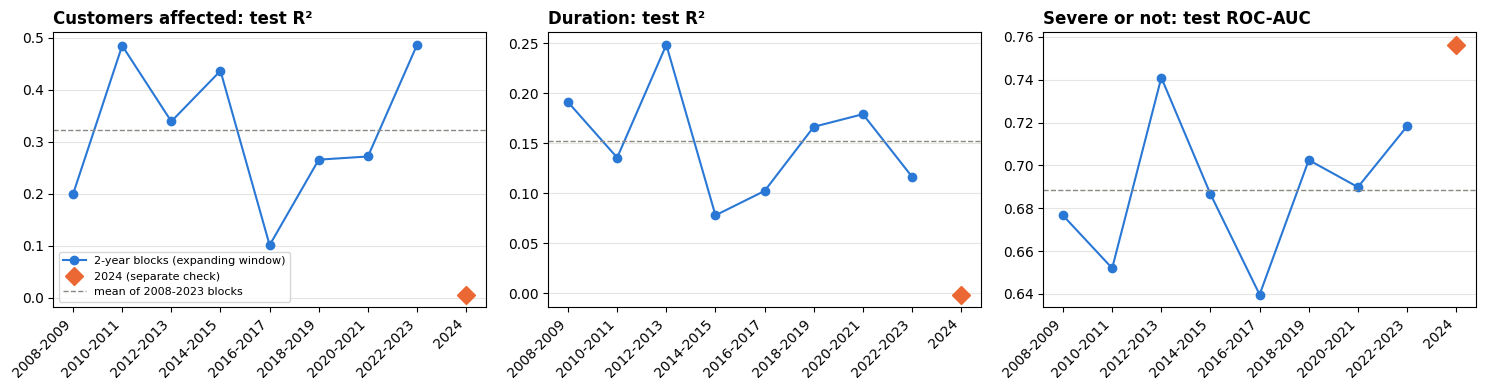

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
x = np.arange(len(wf))
for ax, (col, title) in zip(axes, [("customers_R2", "Customers affected: test R²"), ("duration_R2", "Duration: test R²"),
                                    ("severe_ROC_AUC", "Severe or not: test ROC-AUC")]):
    ax.plot(x[:-1], wf[col].values[:-1], "o-", color="#2a78d6", label="2-year blocks (expanding window)")
    ax.plot(x[-1], wf[col].values[-1], "D", color="#eb6834", markersize=9, label="2024 (separate check)")
    ax.axhline(blocks[col].mean(), color="#8a8984", ls="--", lw=1, label="mean of 2008-2023 blocks")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(wf["test_years"], rotation=45, ha="right")
    ax.grid(axis="y", color="#e6e5e1")
axes[0].legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "exp1_walk_forward.png"), dpi=150)
plt.show()

## 8. Is 2024 different? Evidence from the data

Data properties per year (all outages in the strict-rule table). Severe share uses the Q1 / Q3 thresholds of the 2000–2021 training years, so years are comparable.

In [28]:
def year_profile(df):
    ref = df[df["outage_start"] < pd.Timestamp("2022-01-01")]
    qc = ref["log_customers"].quantile([0.25, 0.75]).values
    qd = ref["log_duration"].quantile([0.25, 0.75]).values
    d = df.assign(year=df["outage_start"].dt.year)
    both = d["log_customers"].notna() & d["log_duration"].notna()
    d["severe"] = np.where(both, ((d["log_customers"] > qc[1]) | (d["log_duration"] > qd[1])).astype(float), np.nan)
    g = d.groupby("year")
    return pd.DataFrame({
        "outages": g.size(),
        "customers known": g["log_customers"].apply(lambda s: s.notna().mean()),
        "duration known": g["log_duration"].apply(lambda s: s.notna().mean()),
        "median customers": g["customers_affected"].median(),
        "median duration (min)": g["outage_duration"].median(),
        "severe share": g["severe"].mean(),
        "share intentional attack": g["cause_reported"].apply(lambda s: (s == "intentional attack").mean()),
        "share severe weather": g["cause_reported"].apply(lambda s: (s == "severe weather").mean()),
        "share with active storm": g["noaa_has_storm"].mean(),
    })


profile = year_profile(tables[WF_RULE])
profile.to_csv(os.path.join(OUT_DIR, "exp1_year_profile.csv"))
display(profile.loc[2014:].round(2))

,outages,customers known,duration known,median customers,median duration (min),severe share,share intentional attack,share severe weather,share with active storm
year,,,,,,,,,
2014,102,0.30,0.98,120000.0,292.5,0.66,0.41,0.42,0.72
2015,114,0.51,0.93,55609.0,176.5,0.36,0.36,0.41,0.66
2016,106,0.42,0.97,0.0,326.0,0.46,0.42,0.25,0.60
2017,132,0.63,0.87,66641.0,329.0,0.48,0.29,0.58,0.77
2018,200,0.52,0.90,29450.0,285.0,0.50,0.26,0.49,0.76
2019,254,0.40,0.96,0.0,179.5,0.32,0.28,0.35,0.69
2020,344,0.48,0.93,1779.0,235.0,0.38,0.23,0.45,0.73
2021,341,0.38,0.96,0.0,239.0,0.40,0.26,0.38,0.70
2022,344,0.35,0.94,0.0,122.0,0.26,0.42,0.26,0.70


## 9. Notes for interpretation

- Each block's model only sees earlier years, as in real use. Early blocks have less training data.
- PR-AUC depends on the share of severe outages in each block (`severe_share`); ROC-AUC does not, so use ROC-AUC to compare blocks.
- The 2024 check uses the same model and setup as the blocks; section 8 shows how the 2024 data itself differs (reporting, missing values, cause mix).

## 10. Does the data really vary over time?

Experiment 1 shows that performance varies between periods. Two questions remain:
1. **Is the variation real, or only noise from small test blocks?** → bootstrap confidence intervals (10.1).
2. **Does the data itself change, not only the model's score?** → target distributions (10.2), cause mix (10.3) and adversarial validation of the input features (10.4).

### 10.1 Bootstrap confidence intervals per test block

Each test block is resampled 500 times (with replacement); the 2.5–97.5 percentiles give a 95% interval. Blocks whose intervals do not overlap differ by more than chance.

value                               ci_low                              ci_high                       
task       customers_reg duration_reg is_severe customers_reg duration_reg is_severe customers_reg duration_reg is_severe
test_years                                                                                                               
2008-2009          0.199        0.191     0.677         0.011        0.101     0.579         0.361        0.271     0.769
2010-2011          0.485        0.136     0.652         0.361        0.056     0.575         0.591        0.215     0.730
2012-2013          0.339        0.249     0.741         0.175        0.158     0.647         0.478        0.319     0.821
2014-2015          0.437        0.078     0.687         0.195       -0.086     0.549         0.580        0.239     0.804
2016-2017          0.102        0.102     0.640        -0.375       -0.078     0.533         0.389        0.266     0.739
2018-2019          0.266        0.166     0.702         0.116        0.092     0.621         0.396        0.235     0.782
2020-2021          0.272        0.179     0.690         0.139        0.131     0.624         0.387        0.222     0.749
2022-2023          0.487        0.116     0.718         0.368        0.051     0.621         0.590        0.174     0.797
2024               0.006       -0.002     0.756        -0.589       -0.082     0.549         0.488        0.074     0.917

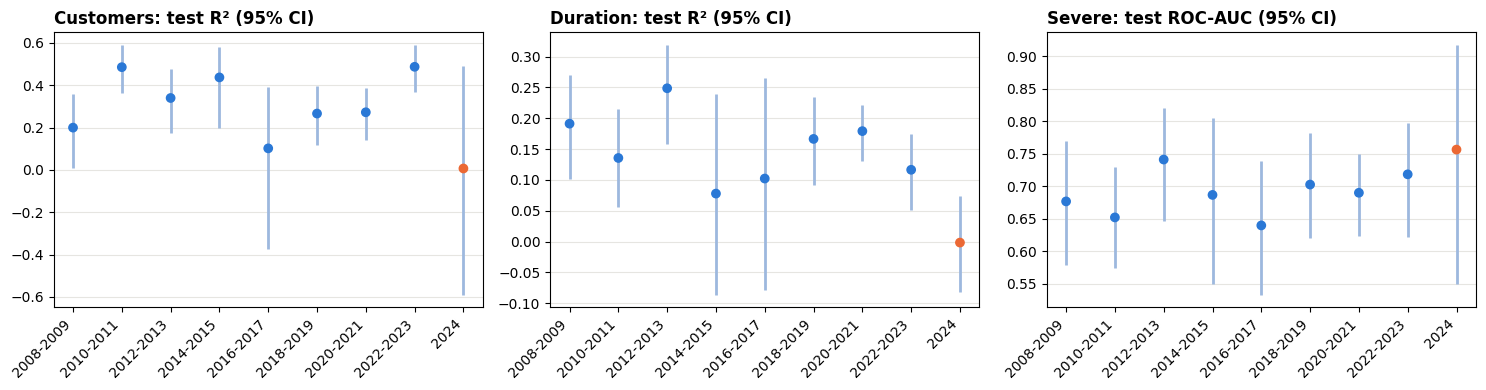

In [29]:
rng = np.random.default_rng(SEED)
B = 500
ci_rows = []
for (block, task), (y, p) in WF_PRED.items():
    kind = TASKS[task][0]
    stats = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if kind == "reg":
            stats.append(r2_score(y[i], p[i]))
        elif len(np.unique(y[i])) == 2:
            stats.append(roc_auc_score(y[i], p[i]))
    point = r2_score(y, p) if kind == "reg" else roc_auc_score(y, p)
    ci_rows.append({"test_years": block, "task": task, "metric": "R2" if kind == "reg" else "ROC_AUC", "n": len(y),
                    "value": point, "ci_low": np.percentile(stats, 2.5), "ci_high": np.percentile(stats, 97.5)})
ci = pd.DataFrame(ci_rows)
ci.to_csv(os.path.join(OUT_DIR, "exp1_bootstrap_ci.csv"), index=False)
display(ci.pivot_table(index="test_years", columns="task", values=["value", "ci_low", "ci_high"], sort=False).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
order = list(wf["test_years"])
for ax, (task, title) in zip(axes, [("customers_reg", "Customers: test R² (95% CI)"), ("duration_reg", "Duration: test R² (95% CI)"),
                                     ("is_severe", "Severe: test ROC-AUC (95% CI)")]):
    c = ci[ci["task"] == task].set_index("test_years").reindex(order)
    x = np.arange(len(c))
    col = ["#eb6834" if b == "2024" else "#2a78d6" for b in c.index]
    ax.errorbar(x, c["value"], yerr=[c["value"] - c["ci_low"], c["ci_high"] - c["value"]], fmt="none", ecolor="#9db8de", lw=2)
    ax.scatter(x, c["value"], color=col, zorder=3)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(c.index, rotation=45, ha="right"); ax.grid(axis="y", color="#e6e5e1")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "exp1_bootstrap_ci.png"), dpi=150); plt.show()

### 10.2 Target distributions by period

Box plots of the two targets (log scale) per period. A shift in the box means the outages themselves changed (not only the model's score).

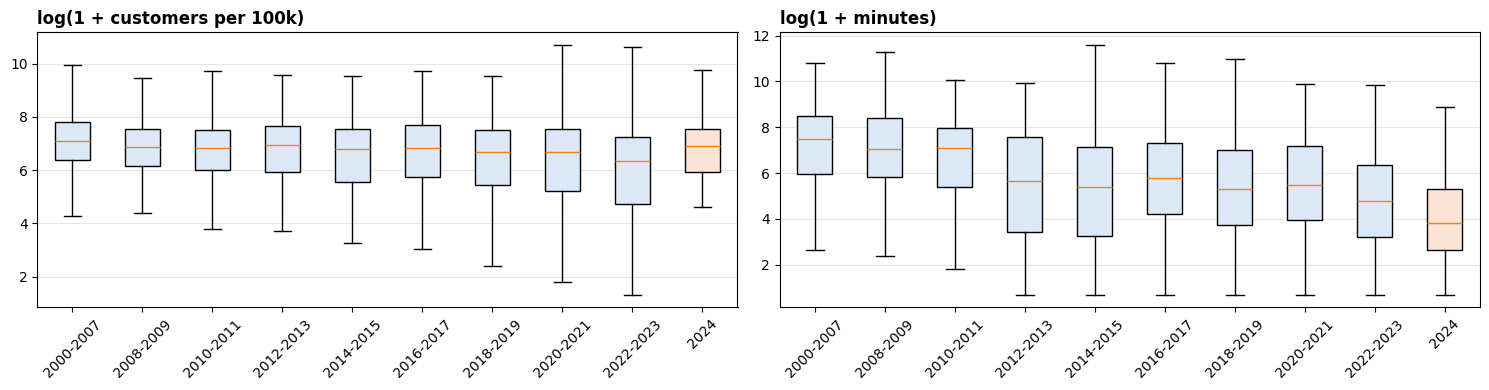

,log_customers,log_duration
period,,
2000-2007,7.10,7.48
2008-2009,6.89,7.04
2010-2011,6.85,7.09
2012-2013,6.96,5.66
2014-2015,6.80,5.41
2016-2017,6.83,5.79
2018-2019,6.68,5.29
2020-2021,6.68,5.48
2022-2023,6.34,4.79


In [30]:
PERIODS = [(2000, 2007)] + WF_BLOCKS + [WF_2024]
def period_label(y):
    for a, b in PERIODS:
        if a <= y <= b:
            return f"{a}-{b}" if b > a else str(a)
dd = tables[WF_RULE].assign(period=tables[WF_RULE]["outage_start"].dt.year.map(period_label))
labels = [f"{a}-{b}" if b > a else str(a) for a, b in PERIODS]
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, (col, title) in zip(axes, [("log_customers", "log(1 + customers per 100k)"), ("log_duration", "log(1 + minutes)")]):
    data_ = [dd.loc[dd["period"] == l, col].dropna().values for l in labels]
    bp = ax.boxplot(data_, labels=labels, showfliers=False, patch_artist=True)
    for k, b in enumerate(bp["boxes"]):
        b.set_facecolor("#fde3d6" if labels[k] == "2024" else "#dbe8f8")
    ax.set_title(title, loc="left", fontweight="bold"); ax.tick_params(axis="x", rotation=45); ax.grid(axis="y", color="#e6e5e1")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "exp1_target_distributions.png"), dpi=150); plt.show()
tq = dd.groupby("period", sort=False)[["log_customers", "log_duration"]].median().reindex(labels)
tq.to_csv(os.path.join(OUT_DIR, "exp1_target_medians.csv"))
display(tq.round(2))

### 10.3 Cause mix by period

Share of each reported cause per period. Non-weather events (for example intentional attacks) are the hardest to predict from weather data, so a changing mix changes how predictable a period is.

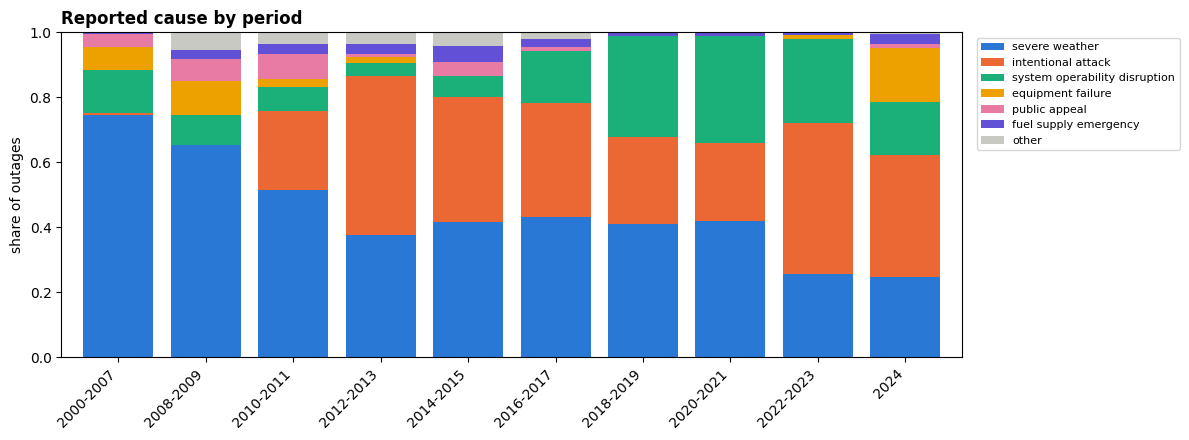

cause_reported,severe weather,intentional attack,system operability disruption,equipment failure,public appeal,fuel supply emergency,other
period,,,,,,,
2000-2007,0.75,0.01,0.13,0.07,0.04,0.00,0.00
2008-2009,0.65,0.00,0.09,0.10,0.07,0.03,0.06
2010-2011,0.52,0.24,0.07,0.02,0.08,0.03,0.04
2012-2013,0.38,0.49,0.04,0.02,0.01,0.03,0.04
2014-2015,0.42,0.38,0.06,0.00,0.04,0.05,0.04
2016-2017,0.43,0.35,0.16,0.00,0.01,0.03,0.02
2018-2019,0.41,0.27,0.31,0.00,0.00,0.01,0.00
2020-2021,0.42,0.24,0.33,0.00,0.00,0.01,0.00
2022-2023,0.26,0.46,0.26,0.01,0.00,0.01,0.00


In [31]:
mix = pd.crosstab(dd["period"], dd["cause_reported"], normalize="index").reindex(labels)
top = mix.mean().sort_values(ascending=False).index[:6]
mix = mix[top].assign(other=1 - mix[top].sum(axis=1))
mix.to_csv(os.path.join(OUT_DIR, "exp1_cause_mix.csv"))
ax = mix.plot(kind="bar", stacked=True, figsize=(12, 4.5), width=0.8,
              color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6", "#c9c9c4"])
ax.set_ylabel("share of outages"); ax.set_xlabel(""); ax.set_title("Reported cause by period", loc="left", fontweight="bold")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8); plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "exp1_cause_mix.png"), dpi=150); plt.show()
display(mix.round(2))

### 10.4 Adversarial validation: do the input features shift?

For each block, a classifier tries to tell the block apart from the **previous** block using only **event-level inputs**: NOAA storm and NWS warning features, time of day / month / weekend, state and region. AUC ≈ 0.5 means the two periods look the same; AUC well above 0.5 means the situations in which outages happen have shifted.
Economy, population and outage-history features are left out on purpose: they are yearly or running averages (for example US GDP per person, global history means), and the El Niño / La Niña `climate_category` is the same for a whole season, so they identify the **calendar year** by construction and would make every comparison trivially AUC = 1. NWS features are left out for blocks that include years before 2006, because they are missing by design there.

,compare,n_prev,n_cur,AUC,top shifted features
0,2008-2009 vs 2010-2011,181,322,0.642,"nws_hours_since_warning, noaa_count_7d, month_cos"
1,2010-2011 vs 2012-2013,322,298,0.693,"nws_hours_since_warning, nws_warn_7d, noaa_cou..."
2,2012-2013 vs 2014-2015,298,216,0.757,"month_sin, start_month, climate_region_Northeast"
3,2014-2015 vs 2016-2017,216,238,0.756,"start_month, month_sin, nws_hours_since_warning"
4,2016-2017 vs 2018-2019,238,454,0.618,"noaa_count_7d, nws_hours_since_warning, nws_wa..."
5,2018-2019 vs 2020-2021,454,685,0.699,"nws_warn_7d, nws_hours_since_warning, noaa_cou..."
6,2020-2021 vs 2022-2023,685,590,0.709,"nws_hours_since_warning, nws_warn_7d, noaa_cou..."
7,2022-2023 vs 2024,590,505,0.795,"nerc_region_PR, climate_region_missing, clean_..."


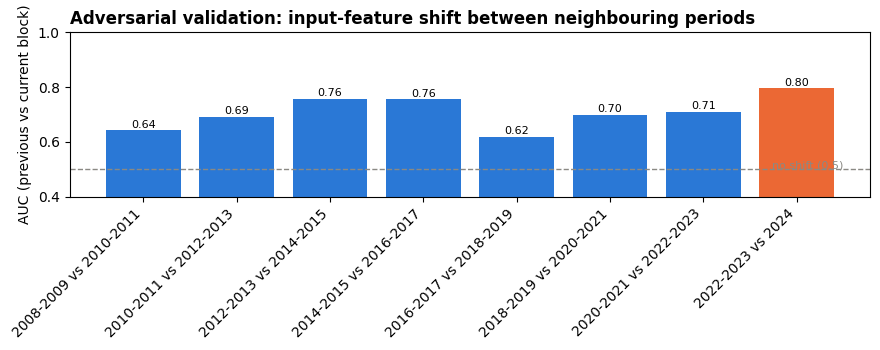

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
EVENT_NUM = [c for c in NOAA_NUM + NWS_NUM + ["start_month", "start_hour", "is_weekend", "month_sin", "month_cos", "hour_sin", "hour_cos",
                                              "n_states_affected"] if c in df.columns]
blocks_all = WF_BLOCKS + [WF_2024]
adv_rows, adv_imp = [], {}
for (a0, a1), (b0, b1) in zip(blocks_all[:-1], blocks_all[1:]):
    yr = df["outage_start"].dt.year
    prev, cur = df[(yr >= a0) & (yr <= a1)], df[(yr >= b0) & (yr <= b1)]
    cols_num = [c for c in EVENT_NUM if not (a0 < 2006 and c.startswith("nws_"))]
    cols_cat = [c for c in cat if c != "climate_category"]
    X = pd.concat([prev, cur])[cols_num + cols_cat]
    y = np.r_[np.zeros(len(prev)), np.ones(len(cur))]
    pipe = Pipeline([("pre", build_preprocessor(cols_num, cols_cat)),
                     ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1))])
    p = cross_val_predict(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    pipe.fit(X, y)
    names = pipe.named_steps["pre"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
    lab_prev = f"{a0}-{a1}" if a1 > a0 else str(a0); lab_cur = f"{b0}-{b1}" if b1 > b0 else str(b0)
    adv_rows.append({"compare": f"{lab_prev} vs {lab_cur}", "n_prev": len(prev), "n_cur": len(cur), "AUC": roc_auc_score(y, p),
                     "top shifted features": ", ".join(i.split("__")[-1] for i in imp.index[:3])})
adv = pd.DataFrame(adv_rows)
adv.to_csv(os.path.join(OUT_DIR, "exp1_adversarial_validation.csv"), index=False)
display(adv.round(3))
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = ["#eb6834" if "2024" in c else "#2a78d6" for c in adv["compare"]]
ax.bar(adv["compare"], adv["AUC"], color=colors)
ax.axhline(0.5, color="#8a8984", ls="--", lw=1); ax.text(len(adv) - 0.5, 0.505, "no shift (0.5)", ha="right", fontsize=8, color="#8a8984")
for i, v in enumerate(adv["AUC"]):
    ax.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_ylim(0.4, 1.0); ax.set_ylabel("AUC (previous vs current block)")
ax.set_title("Adversarial validation: input-feature shift between neighbouring periods", loc="left", fontweight="bold")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "exp1_adversarial_validation.png"), dpi=150); plt.show()

### 10.5 What section 10 shows

Read together with section 8:
- **Bootstrap (10.1):** blocks whose intervals do not overlap differ by more than chance.
- **Targets and causes (10.2, 10.3):** whether the outages themselves change between periods.
- **Adversarial validation (10.4):** whether the input features shift; AUC well above 0.5 means the model is asked to predict a different mix of situations than it learned from.